# HDBSCAN — Hierarchical Density-Based Clustering

## 1. Definition and intuition
HDBSCAN extends the DBSCAN idea by examining density-connected structure across many neighborhood scales and selecting stable clusters. It can handle clusters with different densities better than a single fixed-radius DBSCAN in many settings, and it marks ambiguous points as noise.

## 2. Core concepts
A mutual-reachability distance combines raw distance with core distances, typically
$$
d_{\mathrm{mr}}(a,b)=\max(\operatorname{core}_k(a),\operatorname{core}_k(b),d(a,b)).
$$
A minimum spanning tree under this transformed distance encodes density connectivity. A hierarchy is built across distance scales, condensed using a minimum cluster size, and clusters are selected based on stability across scales.

## 3. Why it works and caveats
The hierarchy allows clusters to be evaluated over a range of density thresholds rather than one epsilon. Its meaning still depends on distance choice, min-cluster-size and min-samples. Some data do not have clear density-stable clusters; high-dimensional distance concentration remains a challenge.

## 4. Library note
HDBSCAN's hierarchy and stability selection are substantially more involved than a short educational implementation. This notebook uses the maintained implementation available in scikit-learn or the optional `hdbscan` package and explains the algorithmic pieces rather than presenting a misleading toy function as a full implementation.

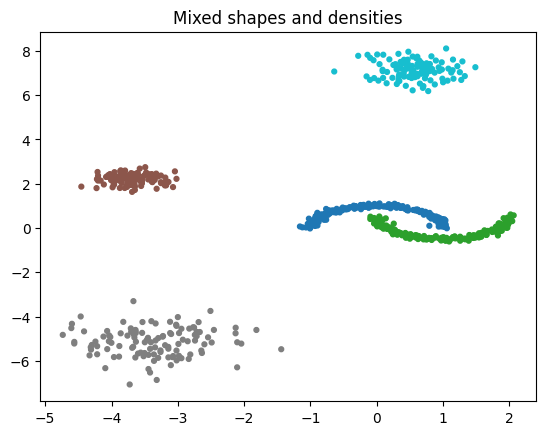

In [1]:
import importlib.util, time
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import make_moons, make_blobs
from sklearn.cluster import DBSCAN, OPTICS
from sklearn.metrics import adjusted_rand_score

SEED=42
X1,y1=make_moons(n_samples=350,noise=.06,random_state=SEED)
X2,y2=make_blobs(n_samples=350,centers=3,cluster_std=[.25,.65,.4],random_state=SEED+1)
X=np.vstack([X1, X2 + np.array([4.0,0.0])])
y_true=np.concatenate([y1, y2+2])
plt.scatter(X[:,0],X[:,1],c=y_true,s=12,cmap="tab10");plt.title("Mixed shapes and densities");plt.show()


## 5. Fit HDBSCAN when available

This cell prefers scikit-learn's HDBSCAN. If unavailable, it tries the separately packaged `hdbscan` implementation; otherwise it explains how to install it and still runs density-based comparison methods.

In [2]:
hdbscan_model=None
hdbscan_backend=None
try:
    from sklearn.cluster import HDBSCAN as SklearnHDBSCAN
    hdbscan_model=SklearnHDBSCAN(min_cluster_size=15,min_samples=8).fit(X)
    hdbscan_backend="sklearn"
except ImportError:
    if importlib.util.find_spec("hdbscan") is not None:
        import hdbscan
        hdbscan_model=hdbscan.HDBSCAN(min_cluster_size=15,min_samples=8).fit(X)
        hdbscan_backend="hdbscan"
    else:
        print("HDBSCAN not installed. Install a recent scikit-learn or run: pip install hdbscan")

db=DBSCAN(eps=.18,min_samples=8).fit(X)
opt=OPTICS(min_samples=8,cluster_method="xi",xi=.05).fit(X)
print("DBSCAN clusters/noise:",len(set(db.labels_)-{-1}),int(np.sum(db.labels_==-1)))
print("OPTICS clusters/noise:",len(set(opt.labels_)-{-1}),int(np.sum(opt.labels_==-1)))
if hdbscan_model is not None:
    print("HDBSCAN backend:",hdbscan_backend)
    print("HDBSCAN clusters/noise:",len(set(hdbscan_model.labels_)-{-1}),int(np.sum(hdbscan_model.labels_==-1)))
    print("HDBSCAN ARI:",round(adjusted_rand_score(y_true,hdbscan_model.labels_),4))


/opt/pyvenv/lib/python3.13/site-packages/sklearn/cluster/_hdbscan/hdbscan.py:722: FutureWarning: The default value of `copy` will change from False to True in 1.10. Explicitly set a value for `copy` to silence this warning.
  warn(


DBSCAN clusters/noise: 6 157
OPTICS clusters/noise: 21 439
HDBSCAN backend: sklearn
HDBSCAN clusters/noise: 5 0
HDBSCAN ARI: 1.0


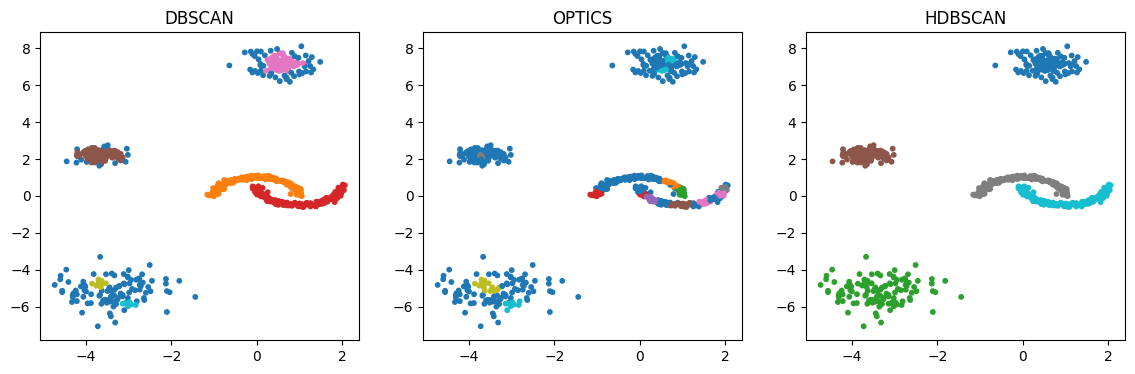

In [3]:
fig, axes=plt.subplots(1,3 if hdbscan_model is not None else 2,figsize=(14,4))
axes[0].scatter(X[:,0],X[:,1],c=db.labels_,s=10,cmap="tab10");axes[0].set_title("DBSCAN")
axes[1].scatter(X[:,0],X[:,1],c=opt.labels_,s=10,cmap="tab10");axes[1].set_title("OPTICS")
if hdbscan_model is not None:
    axes[2].scatter(X[:,0],X[:,1],c=hdbscan_model.labels_,s=10,cmap="tab10");axes[2].set_title("HDBSCAN")
plt.show()


## 6. Hyperparameters and complexity
- `min_cluster_size`: smallest group that can be considered a cluster.
- `min_samples`: density conservatism; increasing it generally makes more points noise.
- `metric`: defines density geometry.
- Approximate complexity depends on neighbor search, minimum-spanning-tree construction and hierarchy operations; naive pairwise distance approaches can require $O(n^2)$ storage. Implementations often exploit spatial indexes or optimized MST operations.
- For millions of points, use scalable neighbor search, low-dimensional feature representations and benchmark memory. GPU support depends on the implementation (for example, RAPIDS cuML in supported environments).
- As with other density methods, scaling numeric features matters when units have different magnitudes.

## 7. Best practices and synthesis
Compare stability, noise fraction and domain meaning across `min_cluster_size` and `min_samples`. HDBSCAN gives a density hierarchy and stable clusters; it does not remove the need to inspect whether distance and density are meaningful.

In [4]:
assert len(db.labels_)==len(X) and len(opt.labels_)==len(X)
if hdbscan_model is not None:
    assert len(hdbscan_model.labels_)==len(X)
try:
    from sklearn.cluster import HDBSCAN as _HDB
    _HDB(min_cluster_size=2)
except ImportError:
    pass
print("All HDBSCAN notebook checks passed (library path conditional).")


All HDBSCAN notebook checks passed (library path conditional).
